# Threadfin from start to finish: public GEO files to clone-level biology

This notebook is a complete, tested walk-through of Threadfin on real data. It starts from an empty folder,
downloads a published paired single-cell RNA + B-cell receptor (BCR) sequencing dataset from GEO, builds
everything Threadfin needs, runs the analysis, and explains every output. If you have never used Threadfin
— or never analysed B-cell clones — start here.

**The dataset.** Germinal-centre (GC) B cells from ten H2B–mCherry *division-reporter* mice immunised with
the SARS-CoV-2 receptor-binding domain (RBD), from Merkenschlager *et al.*, *Nature* 2025
([GSE287123](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE287123)). In these mice a pulse of
H2B–mCherry is diluted every time a cell divides, so after a 36-hour chase the cells that divided most
are mCherry-*low*. Two cohorts were sorted differently:

| Cohort | Mice | Sorted by | What each cell was labelled with |
|---|---|---|---|
| RBD protein | M1–M5 | RBD-bait binding × mCherry | `RBD+` / `RBD-` and `mCherry-low` / `mCherry-high` |
| RBD mRNA | M6–M10 | light zone / dark zone × mCherry | `LZ` / `DZ` and `mCherry-low` / `mCherry-high` |

Every cell carries a **hashtag** antibody that says which mouse it came from, and all ten mice were pooled
into four sequencing libraries (tubes A–D). This is the dataset of Figure 4 of the Threadfin manuscript.

**What you will learn**

1. how to set up an environment for Threadfin and Dandelion;
2. how to download and read 10x gene-expression, hashtag and AIRR files;
3. how to assign cells to mice (hashtag demultiplexing) and to clones (paired heavy + light chains);
4. how to build an expression embedding that does not "see" the receptor;
5. how to run Threadfin in one call, and how to read every number it reports;
6. how to test whether measured annotations (division, antigen binding, zone) explain differences between
   clones — and how to recognise when a test cannot separate biology from the sequencing library.

**Resources.** About 600 MB of downloads, about 8 GB of memory at the peak (16 GB recommended), no GPU and
no R. Tested on 8 CPU cores: about 6 minutes from the first to the last cell, plus the download; most of the
time goes to reading the matrices, Dandelion's clone calling and the clone-map layout search.

**How to read this notebook.** Every step has three parts: **what** the code does, **why** it is done
this way, and **what to look for** in the output. Text in *italics* marks things that commonly go wrong.

## Step 0 — Set up the environment (once, in a terminal)

**What.** Create an isolated Python environment with Threadfin, Dandelion (which defines clones from receptor
sequences) and Jupyter.

```bash
# 1. a fresh environment, so nothing else on your computer interferes
conda create -n threadfin -c conda-forge python=3.11 pip -y
conda activate threadfin

# 2. Threadfin from GitHub, Dandelion from PyPI, and Jupyter
pip install "git+https://github.com/Reynold4k/Threadfin.git"
pip install "sc-dandelion==0.5.7" "matplotlib<3.9" jupyterlab ipykernel

# 3. make the environment available as a Jupyter kernel (with a fixed hash seed, see below), then open
#    the notebook
python -m ipykernel install --user --name threadfin --display-name "Python (threadfin)" --env PYTHONHASHSEED 0
jupyter lab docs/tutorials/05_end_to_end_tutorial.ipynb
```

The same environment can be created from [`environment.yml`](environment.yml) with
`conda env create -f docs/tutorials/environment.yml`.

**Why.**

* *An isolated environment* keeps the package versions this tutorial was tested with (listed in the last
  cell) and keeps Threadfin's dependencies from changing packages that other projects rely on.
* *`matplotlib<3.9`* is needed by Dandelion 0.5.7, which uses a matplotlib function removed in version 3.9
  (`matplotlib.cm.get_cmap`); Dandelion's package metadata does not say so, so pip would otherwise install a
  newer matplotlib and `import dandelion` would fail. Threadfin itself works with matplotlib 3.7 and later.
* *Python 3.11* is the version the manuscript analyses used; Threadfin supports 3.10–3.12.
* *Dandelion* is only needed to define clones. If you already have clone ids (one per cell), you can skip it
  and put them in `adata.obs["clone_id"]`.
* *`--env PYTHONHASHSEED 0`* makes clone calling reproducible. Dandelion's clone assignment depends on the
  order in which Python iterates over sets of sequences, and that order is randomised in every new Python
  session unless `PYTHONHASHSEED` is fixed. Without it, repeated runs of this notebook give a few clones
  more or fewer (for example 8,729 or 8,731 clones) and slightly different downstream numbers; the
  conclusions do not change. The first code cell reports whether the seed is set.
* No GPU, R or compiler is needed.

*If `pip install` fails on a cluster, check that you are inside the activated environment (`which python`
should point into it). If `import dandelion` fails with "cannot import name 'get_cmap'", run
`pip install "matplotlib<3.9"`.*

**What to look for.** The next cell should print the versions without errors.

In [1]:
import importlib
import os
import platform
import sys
import warnings
from importlib.metadata import version

print("Python", sys.version.split()[0], "on", platform.system())
with warnings.catch_warnings():               # silence import-time notices of third-party packages
    warnings.simplefilter("ignore")
    for module, dist in [("threadfin", "threadfin"), ("dandelion", "sc-dandelion"), ("scanpy", "scanpy"),
                         ("anndata", "anndata"), ("numpy", "numpy"), ("pandas", "pandas"), ("scipy", "scipy"),
                         ("sklearn", "scikit-learn"), ("umap", "umap-learn"), ("leidenalg", "leidenalg"),
                         ("igraph", "igraph"), ("matplotlib", "matplotlib")]:
        importlib.import_module(module)
        print(f"{module:12s} {version(dist)}")

import threadfin as tf
assert tuple(int(x) for x in tf.__version__.split(".")[:3]) >= (4, 3, 1), "this tutorial needs threadfin >= 4.3.1"
seed = os.environ.get("PYTHONHASHSEED")
print(f"\nPYTHONHASHSEED = {seed}" if seed is not None else
      "\nPYTHONHASHSEED is not set: clone calls may differ slightly between runs (see Step 0)")

Python 3.11.17 on Linux


threadfin    4.3.1


dandelion    0.5.7
scanpy       1.11.5
anndata      0.12.19
numpy        2.4.6
pandas       2.3.3
scipy        1.17.1
sklearn      1.9.1


umap         0.5.12
leidenalg    0.12.0
igraph       1.0.0
matplotlib   3.8.4

PYTHONHASHSEED = 0


## Step 1 — Download the data from GEO

**What.** Fetch 16 files: for each of the four sequencing tubes (A–D), the gene-expression + hashtag count
matrix (three files in the 10x "matrix market" format) and the AIRR rearrangement table of the BCR library.
Each file is checked against its MD5 checksum, and files that are already present are not downloaded again.

**Why.** GEO stores one supplementary file set per GEO sample (GSM). The tubes are the *sequencing
libraries*; each tube contains cells of all ten mice. The four files per tube are:

| File | Content |
|---|---|
| `*_GEX_HTO_matrix.mtx.gz` | counts: features × cells (sparse) |
| `*_GEX_HTO_features.tsv.gz` | one row per feature: ~32,000 genes plus 10 hashtag antibodies |
| `*_GEX_HTO_barcodes.tsv.gz` | one row per cell barcode |
| `*_airr_rearrangement.tsv.gz` | one row per receptor *chain* (contig) per cell, in the AIRR standard |

**What to look for.** Each file ends with `ok`. A failed checksum means a broken download: delete the file
and run the cell again.

In [2]:
import hashlib
import urllib.request
from pathlib import Path

DATA = Path("data/GSE287123")
DATA.mkdir(parents=True, exist_ok=True)

TUBES = {  # tube: (GEO sample of the expression library, GEO sample of the BCR library, library name)
    "A": ("GSM8739143", "GSM8739145", "Rebutal_4-5_Tube_A"),
    "B": ("GSM8739146", "GSM8739148", "Rebutal_4-5_Tube_B"),
    "C": ("GSM8739149", "GSM8739151", "Rebutal_4-5_Tube_C"),
    "D": ("GSM8739152", "GSM8739154", "Rebutal_4-5_Tube_D"),
}
MD5 = {
    "GSM8739143_Rebutal_4-5_Tube_A_GEX_HTO_barcodes.tsv.gz": "589eb6503c2ac806de9b2db3fb81e433",
    "GSM8739143_Rebutal_4-5_Tube_A_GEX_HTO_features.tsv.gz": "f89add0fc8f0a6126328592c4f98e2b3",
    "GSM8739143_Rebutal_4-5_Tube_A_GEX_HTO_matrix.mtx.gz": "871c4c27db40fef6e85b22925f669939",
    "GSM8739146_Rebutal_4-5_Tube_B_GEX_HTO_barcodes.tsv.gz": "5ba3969c131f02d8bcb058f5650e3f87",
    "GSM8739146_Rebutal_4-5_Tube_B_GEX_HTO_features.tsv.gz": "fd0d96207c7e96ce218a7a73564c204a",
    "GSM8739146_Rebutal_4-5_Tube_B_GEX_HTO_matrix.mtx.gz": "6e7891bf6cf9a406aa94847ccab4028e",
    "GSM8739149_Rebutal_4-5_Tube_C_GEX_HTO_barcodes.tsv.gz": "a8a6ef4a3016159f776ca60b0c1feb3d",
    "GSM8739149_Rebutal_4-5_Tube_C_GEX_HTO_features.tsv.gz": "653fa5bdfd7707dc82a84e1281e36b69",
    "GSM8739149_Rebutal_4-5_Tube_C_GEX_HTO_matrix.mtx.gz": "fc59fab812357466c2d47a680d0491ef",
    "GSM8739152_Rebutal_4-5_Tube_D_GEX_HTO_barcodes.tsv.gz": "f4e934d72a9b49c3c479a3a54d01d3da",
    "GSM8739152_Rebutal_4-5_Tube_D_GEX_HTO_features.tsv.gz": "475ef5a635671345d145aa0a42782b22",
    "GSM8739152_Rebutal_4-5_Tube_D_GEX_HTO_matrix.mtx.gz": "76987b838c609f0a68887ec63fb8cf2c",
    "GSM8739145_Rebutal_4-5_Tube_A_airr_rearrangement.tsv.gz": "c673685b5ebc2179e1cdbeb54877086a",
    "GSM8739148_Rebutal_4-5_Tube_B_airr_rearrangement.tsv.gz": "e6460e998ff9d2099fe8cff671530f48",
    "GSM8739151_Rebutal_4-5_Tube_C_airr_rearrangement.tsv.gz": "ac1ceacd942cc268b9ce424b10287669",
    "GSM8739154_Rebutal_4-5_Tube_D_airr_rearrangement.tsv.gz": "08bce424fa0e9d1acdf7943062e75882",
}


def md5(path, chunk=1 << 22):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


def fetch(name):
    gsm = name.split("_")[0]
    url = f"https://ftp.ncbi.nlm.nih.gov/geo/samples/{gsm[:-3]}nnn/{gsm}/suppl/{name}"
    path = DATA / name
    if path.exists() and md5(path) == MD5[name]:
        return f"{name}: already present, ok"
    for attempt in range(3):                       # GEO occasionally drops a connection
        try:
            urllib.request.urlretrieve(url, path)
            break
        except OSError as err:
            print(f"  retrying {name} ({err})")
    if md5(path) != MD5[name]:
        raise RuntimeError(f"checksum mismatch for {name}; delete it and run this cell again")
    return f"{name}: {path.stat().st_size / 1e6:.1f} MB, ok"


for name in MD5:
    print(fetch(name))

GSM8739143_Rebutal_4-5_Tube_A_GEX_HTO_barcodes.tsv.gz: 0.1 MB, ok


GSM8739143_Rebutal_4-5_Tube_A_GEX_HTO_features.tsv.gz: 0.3 MB, ok


GSM8739143_Rebutal_4-5_Tube_A_GEX_HTO_matrix.mtx.gz: 198.4 MB, ok


GSM8739146_Rebutal_4-5_Tube_B_GEX_HTO_barcodes.tsv.gz: 0.1 MB, ok


GSM8739146_Rebutal_4-5_Tube_B_GEX_HTO_features.tsv.gz: 0.3 MB, ok


...

GSM8739152_Rebutal_4-5_Tube_D_GEX_HTO_matrix.mtx.gz: 118.6 MB, ok


GSM8739145_Rebutal_4-5_Tube_A_airr_rearrangement.tsv.gz: 5.8 MB, ok


GSM8739148_Rebutal_4-5_Tube_B_airr_rearrangement.tsv.gz: 6.4 MB, ok


GSM8739151_Rebutal_4-5_Tube_C_airr_rearrangement.tsv.gz: 1.9 MB, ok


GSM8739154_Rebutal_4-5_Tube_D_airr_rearrangement.tsv.gz: 3.5 MB, ok


## Step 2 — Read gene expression and hashtag counts

**What.** Read each tube's count matrix into an [AnnData](https://anndata.readthedocs.io) object (cells ×
features) and split the features into genes (`Gene Expression`) and hashtag antibodies (`Antibody Capture`).

**Why.** AnnData is the standard container of the scverse ecosystem (Scanpy, scirpy, Dandelion, Threadfin):
`adata.X` holds the counts, `adata.obs` one row of annotation per cell, `adata.var` one row per gene, and
`adata.obsm` cell embeddings. The hashtag counts are kept aside: they are used only to find out which mouse
each cell came from, never as expression.

Cell barcodes repeat between libraries (the same 16-letter barcode can occur in tubes A and B), so every
barcode is prefixed with its tube (`A|AAACCAAAG...-1`). The same prefix is added to the BCR table later, so
the two can be matched.

**What to look for.** About 8,000–13,000 barcodes per tube, 32,285 genes and 10 hashtags.

In [3]:
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad

sc.settings.verbosity = 1
tubes = {}
for tube, (gsm_gex, gsm_bcr, library) in TUBES.items():
    a = sc.read_10x_mtx(DATA, prefix=f"{gsm_gex}_{library}_GEX_HTO_", var_names="gene_symbols",
                        gex_only=False, make_unique=True)
    a.obs_names = [f"{tube}|{barcode}" for barcode in a.obs_names]
    a.obs["tube"] = tube
    tubes[tube] = a
    kinds = a.var["feature_types"].value_counts().to_dict()
    print(f"tube {tube}: {a.n_obs:,} barcodes; features {kinds}")

tube A: 19,287 barcodes; features {'Gene Expression': 32285, 'Antibody Capture': 10}


tube B: 16,412 barcodes; features {'Gene Expression': 32285, 'Antibody Capture': 10}


tube C: 5,870 barcodes; features {'Gene Expression': 32285, 'Antibody Capture': 10}


tube D: 9,935 barcodes; features {'Gene Expression': 32285, 'Antibody Capture': 10}


## Step 3 — Which mouse did each cell come from? (hashtag demultiplexing)

**What.** For every hashtag, decide which cells are positive. A cell positive for exactly one hashtag is a
*singlet* and is assigned to that hashtag's mouse; positive for several, it is a *doublet* (two cells in
one droplet); positive for none, it is *negative*. Doublets and negatives are removed.

**Why.** Pooling mice into one library is cheap and removes library-to-library differences between mice, but
it means the mouse identity must be recovered from the hashtag counts. Each hashtag's counts are
log-transformed and centred (a centred log-ratio, CLR), and split into "background" and "signal" by
two-group k-means — the simple rule used for the manuscript. Doublets would look like cells in two states at
once, so they must not reach the clone analysis.

The hashtag *names* also carry the sorting gate of that tube, e.g. `M1_RBD_neg_mCherry_low` means mouse 1,
RBD-bait-negative, mCherry-low (recently divided).

**What to look for.** Most barcodes should be singlets; a few percent doublets and negatives are normal.

In [4]:
from sklearn.cluster import KMeans


def demultiplex(hto_counts: pd.DataFrame, min_total: int = 5) -> pd.Series:
    x = hto_counts.to_numpy(dtype=float)
    clr = np.log1p(x) - np.log1p(x).mean(axis=0, keepdims=True)
    positive = np.zeros_like(clr, dtype=bool)
    for j in range(clr.shape[1]):
        km = KMeans(2, n_init=10, random_state=0).fit(clr[:, [j]])
        positive[:, j] = km.labels_ == int(np.argmax(km.cluster_centers_.ravel()))
    n_pos = positive.sum(axis=1)
    call = np.where(n_pos == 1, np.asarray(hto_counts.columns)[positive.argmax(axis=1)], "negative")
    call = np.where(n_pos > 1, "doublet", call)
    call = np.where(x.sum(axis=1) < min_total, "negative", call)
    return pd.Series(call, index=hto_counts.index, name="hashtag")


expression = []
for tube, a in tubes.items():
    is_hto = (a.var["feature_types"] == "Antibody Capture").to_numpy()
    hto = pd.DataFrame(a[:, is_hto].X.toarray(), index=a.obs_names, columns=a.var_names[is_hto])
    gex = a[:, ~is_hto].copy()
    gex.obs["hashtag"] = demultiplex(hto).values
    kind = gex.obs["hashtag"].where(gex.obs["hashtag"].isin(["doublet", "negative"]), "singlet")
    print(f"tube {tube}:", kind.value_counts().to_dict())
    expression.append(gex[kind.eq("singlet").to_numpy()].copy())

adata = ad.concat(expression, join="outer", fill_value=0)
print(f"\n{adata.n_obs:,} singlet cells x {adata.n_vars:,} genes")

tube A: {'singlet': 13141, 'doublet': 3079, 'negative': 3067}


tube B: {'singlet': 10881, 'doublet': 4484, 'negative': 1047}


tube C: {'singlet': 4802, 'doublet': 879, 'negative': 189}


tube D: {'singlet': 7364, 'doublet': 2451, 'negative': 120}



36,188 singlet cells x 32,285 genes


## Step 4 — One table of mice, cohorts and sorting gates

**What.** Turn each hashtag name into separate columns: `donor` (the mouse), `arm` (protein or mRNA
immunisation), `rbd_bait`, `zone_gate`, `division_gate`, and a `sample` column naming the mouse × gate
population.

**Why.** Threadfin needs to know, for each cell, *which individual it came from* (`donor`) — clones are
defined within individuals, and tests shuffle labels within individuals. The gates are the measurements we
will later test against the clones. They are deliberately **not** given to Threadfin when it builds the
clone profiles.

**What to look for.** The cross-table of tubes against gates is the key design feature of this experiment.
In the protein cohort the recently divided (mCherry-low) cells were sequenced in tubes A and C, in the mRNA
cohort in tubes B and D. A difference between tubes therefore cannot imitate a division effect in the same
direction in both cohorts — we use this at Step 13.

In [5]:
tag = adata.obs["hashtag"].astype(str)
adata.obs["donor"] = tag.str.split("_").str[0]
adata.obs["arm"] = np.where(tag.str.contains("_RBD_"), "RBD protein", "RBD mRNA")
adata.obs["rbd_bait"] = tag.map(lambda s: "RBD+" if "_RBD_pos" in s else ("RBD-" if "_RBD_neg" in s else None))
adata.obs["zone_gate"] = tag.map(lambda s: "LZ" if "_LZ_" in s else ("DZ" if "_DZ_" in s else None))
adata.obs["division_gate"] = np.where(tag.str.contains("mCherry_low"), "mCherry-low", "mCherry-high")
adata.obs["sample"] = (adata.obs["donor"] + "_" + adata.obs["rbd_bait"].fillna(adata.obs["zone_gate"]).astype(str)
                       + "_" + adata.obs["division_gate"])
for col in ["donor", "arm", "rbd_bait", "zone_gate", "division_gate", "sample", "tube"]:
    adata.obs[col] = adata.obs[col].astype("category")

print(adata.obs.groupby("arm", observed=True)["donor"].nunique().rename("mice").to_string(), "\n")
print("Cells by tube and gate (protein cohort):")
print(pd.crosstab(adata.obs["tube"], [adata.obs["rbd_bait"], adata.obs["division_gate"]]))
print("\nCells by tube and gate (mRNA cohort):")
print(pd.crosstab(adata.obs["tube"], [adata.obs["zone_gate"], adata.obs["division_gate"]]))

arm
RBD mRNA       5
RBD protein    5 

Cells by tube and gate (protein cohort):
rbd_bait              RBD+                     RBD-            
division_gate mCherry-high mCherry-low mCherry-high mCherry-low
tube                                                           
A                        0           0            0       11624
B                        0           0         9232           0
C                        0        3361            0           0
D                     4992           0            0           0

Cells by tube and gate (mRNA cohort):
zone_gate               DZ                       LZ            
division_gate mCherry-high mCherry-low mCherry-high mCherry-low
tube                                                           
A                        0           0         1517           0
B                        0           0            0        1649
C                     1441           0            0           0
D                        0        2372          

## Step 5 — A quick look at cell quality

**What.** Compute the usual per-cell quality metrics: genes detected, total counts and the percentage of
mitochondrial reads.

**Why.** Damaged cells (few genes, many mitochondrial reads) can form artificial clusters. The cells of this
study were FACS-sorted GC B cells and the manuscript analysed all singlets, so we only *look* at the
metrics here and keep every cell, which lets you compare your numbers with the paper. For your own data, a
typical starting filter is ≥ 200 genes, ≥ 500 counts and < 15–20 % mitochondrial reads; choose thresholds
from these plots rather than copying them.

**What to look for.** One main population per tube, without a large low-quality tail.

In [6]:
adata.var["mt"] = adata.var_names.str.startswith("mt-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)
print(adata.obs.groupby("tube", observed=True)[["n_genes_by_counts", "total_counts", "pct_counts_mt"]]
      .median().round(1).to_string())
sc.pl.violin(adata, ["n_genes_by_counts", "total_counts", "pct_counts_mt"], groupby="tube", jitter=False,
             multi_panel=True)

      n_genes_by_counts  total_counts  pct_counts_mt
tube                                                
A                2825.0        7374.0            4.8
B                2742.0        7836.0            3.3
C                3719.0       12227.5            3.9
D                2666.5        7147.0            4.5


<Figure size 2413.8x480 with 3 Axes>

## Step 6 — Read the B-cell receptor sequences (AIRR tables)

**What.** Read the four AIRR rearrangement tables. Each row is one receptor chain (*contig*) assembled for
one cell: a heavy chain (`IGH`) or a light chain (`IGK` / `IGL`), with its V, D and J gene calls, its
junction (the CDR3 region plus the conserved flanking codons) and whether it is productive. Barcodes get the
same tube prefix as the expression data.

**Why.** The receptor is the clone's barcode: all cells that descend from one activated naive B cell share
one heavy- and one light-chain rearrangement (apart from somatic mutations). The table must be
*contig-level* — one row per chain — because clone definition needs to pair each cell's heavy chain with its
light chain.

**What to look for.** Most cells with a BCR have exactly one productive heavy and one productive light chain.

In [7]:
contigs = []
for tube, (gsm_gex, gsm_bcr, library) in TUBES.items():
    t = pd.read_csv(DATA / f"{gsm_bcr}_{library}_airr_rearrangement.tsv.gz", sep="\t", low_memory=False)
    t["cell_id"] = tube + "|" + t["cell_id"].astype(str)
    contigs.append(t)
contigs = pd.concat(contigs, ignore_index=True)
contigs = contigs[contigs["cell_id"].isin(adata.obs_names)]            # singlets only
contigs["locus"] = contigs["v_call"].astype(str).str[:3]
productive = contigs[contigs["productive"].astype(str).str.upper().isin(["T", "TRUE"])]
chains = productive.groupby(["cell_id", "locus"]).size().unstack(fill_value=0)
heavy = chains.get("IGH", 0)
light = chains.get("IGK", 0) + chains.get("IGL", 0)
print(f"{len(contigs):,} contigs from {contigs['cell_id'].nunique():,} singlet cells")
print(f"cells with a productive heavy chain: {(heavy > 0).sum():,}; "
      f"with heavy and light: {((heavy > 0) & (light > 0)).sum():,}; "
      f"exactly one of each: {((heavy == 1) & (light == 1)).sum():,}")

39,788 contigs from 21,939 singlet cells
cells with a productive heavy chain: 16,667; with heavy and light: 15,870; exactly one of each: 14,021


## Step 7 — Define clones with Dandelion (paired chains, within each mouse)

**What.** Group cells into clones with Dandelion's definition: same heavy-chain V gene, J gene and junction
length, same light-chain V gene, J gene and junction length, and junction amino-acid sequences at least 85 %
identical. Clones are called separately within each mouse, and the mouse is written into the clone id.

**Why.**

* *Paired chains.* Defining clones on the heavy chain alone merges unrelated cells that happen to use the same
  heavy chain; in this dataset the light chain splits a 791-cell "clone" into real clones of at most 254
  cells, and clonal coherence increases when the light chain is used.
* *Within each mouse.* Two mice cannot share a clone. Calling clones within mice prevents public
  (convergent) receptors from joining cells of different animals.
* *85 % junction identity* allows for somatic hypermutation inside the CDR3.
* *Cells without a heavy chain get no clone.* Dandelion can group cells whose heavy chain was not recovered
  by their light chain alone, but light-chain rearrangements are far less diverse, so such groups join
  unrelated cells. Threadfin (≥ 4.3.1) leaves these cells without a clone; the log line says how many.

**What to look for.** Most clones are captured as one cell. Threadfin profiles every clone with **at least
two** cells: a clone seen once has no second cell to compare, so it cannot answer whether cells of one clone
share a state. Clones of two or three cells are kept — Threadfin shrinks their profiles instead of
discarding them (Step 9). Expect about 8,700 clones, of which about 1,880 have ≥ 2 cells (the manuscript
analysed 1,887), and a log line saying that about 5,300 cells without a heavy chain were left without a
clone. With `PYTHONHASHSEED=0` (Step 0) you get exactly the numbers shown here; without it, a few clones
more or fewer.

In [8]:
contigs["donor"] = contigs["cell_id"].map(adata.obs["donor"].astype(str))
clone_ids = tf.tl.define_clones_dandelion(contigs, cell_key="cell_id", donor_key="donor", identity=0.85)
adata.obs["clone_id"] = clone_ids.reindex(adata.obs_names).values

sizes = adata.obs["clone_id"].dropna().value_counts()
print(f"cells with a clone: {adata.obs['clone_id'].notna().sum():,} of {adata.n_obs:,}")
print(f"clones: {len(sizes):,}; with >= 2 cells: {(sizes >= 2).sum():,}; "
      f"exactly 2: {(sizes == 2).sum():,}; >= 10: {(sizes >= 10).sum():,}; largest: {sizes.max()}")

[threadfin]   M1: 2333 clones over 6018 cells


[threadfin]   M10: 420 clones over 840 cells


[threadfin]   M2: 1868 clones over 3277 cells


[threadfin]   M3: 1622 clones over 3446 cells


[threadfin]   M4: 1743 clones over 3519 cells


...

[threadfin]   M8: 269 clones over 460 cells


[threadfin]   M9: 556 clones over 1159 cells


[threadfin] 5,272 cells without a heavy chain were grouped by their light chain alone; they are left without a clone (require_heavy_chain=False keeps them)


[threadfin] Dandelion (heavy + light, identity 0.85): 16,667 cells, 8,734 clones, 1,885 with >= 2 cells, largest 253


cells with a clone: 16,667 of 36,188
clones: 8,734; with >= 2 cells: 1,885; exactly 2: 945; >= 10: 158; largest: 253


## Step 8 — An expression embedding that does not see the receptor

**What.** `tf.pp.prepare_embedding` normalises each cell to 10,000 counts, takes `log(1 + x)`, removes all
immunoglobulin (and T-cell receptor) genes, picks the 3,000 most variable genes, scales them and reduces them
to 30 principal components, stored in `adata.obsm["X_threadfin"]`. We also draw an ordinary cell-level UMAP,
for display only.

**Why.**

* *Removing immunoglobulin genes* is essential: cells of one clone express the same V genes, so without this
  step the expression embedding would already "know" the clone and every clonal test would be circular.
* *30 principal components* summarise cell state while discarding much of the gene-level noise; all
  Threadfin statistics are computed in this space, never on a 2-D UMAP.
* The raw counts in `adata.X` are left untouched; the normalised values go to `adata.layers["log_norm"]`.

**What to look for.** On the cell UMAP, mCherry-low (recently divided) cells and mCherry-high cells occupy
different but overlapping regions.

[threadfin] HVG: 3000 genes (receptor genes excluded: 652 in var).


embedding (36188, 30); receptor genes excluded: 652


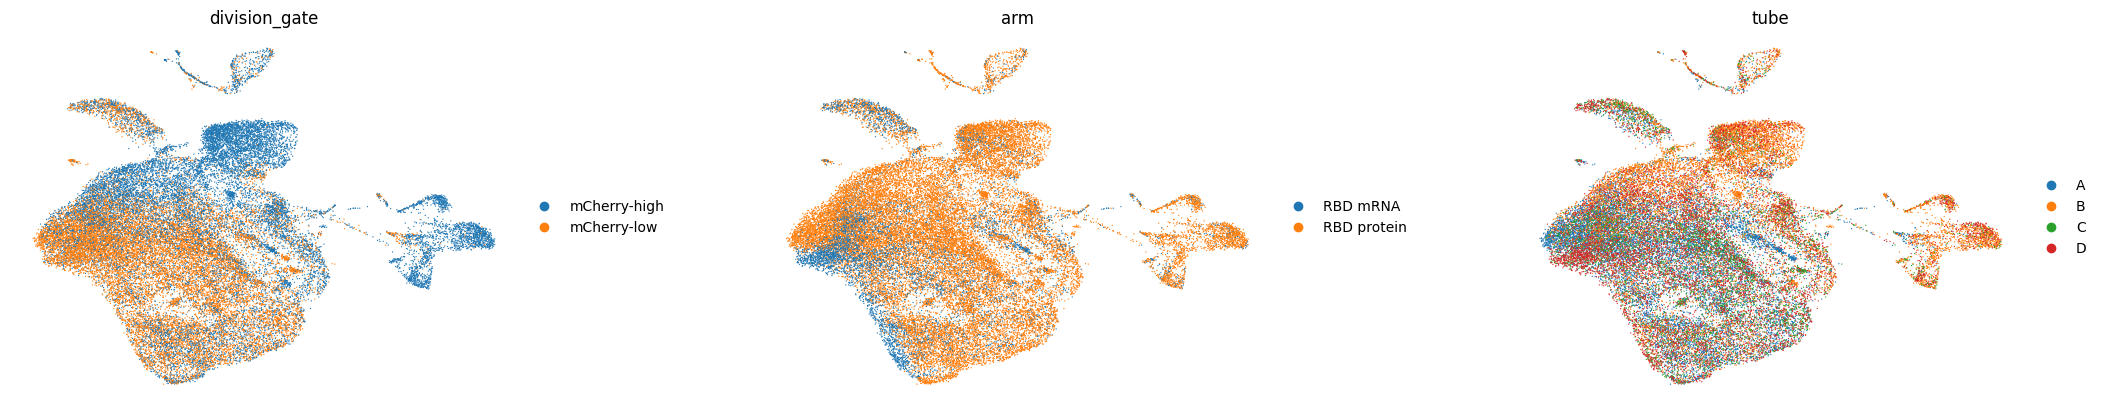

In [9]:
tf.pp.prepare_embedding(adata, n_top_genes=3000, n_comps=30)
removed = int(adata.var["threadfin_receptor_gene"].sum())
print(f"embedding {adata.obsm['X_threadfin'].shape}; receptor genes excluded: {removed}")

sc.pp.neighbors(adata, use_rep="X_threadfin", n_neighbors=15, random_state=0)
sc.tl.umap(adata, random_state=0)
sc.pl.umap(adata, color=["division_gate", "arm", "tube"], wspace=0.35, frameon=False)

## Step 9 — Run Threadfin

**What.** One call runs the whole analysis: clone profiles, the clonal-coherence test, the clone map,
clonal programmes with bootstrap stability, and clone-level tests of the annotations listed in `test`.

**Why these arguments.**

* `donor_key="donor"`: tests shuffle labels among clones of the same mouse.
* `sample_key="donor"`: each cell is described **relative to the other cells of its own mouse** (the
  *sampling context*). The context must be a nuisance variable. Here the `sample` column (mouse × gate)
  would be wrong, because centring on it would subtract exactly the gate differences we want to test.
  Rule of thumb: use the donor, or a technical batch, as the context — never a variable you want to study.
* `basis="X_threadfin"`: the embedding from Step 8.
* `test=[...]`: annotations to test against the clone profiles afterwards. They are **not** used to build
  the profiles.

**How a clone profile is built** (details in [Methods](../METHODS.md)): each cell's coordinates are centred
on its mouse; each cell is averaged with its 15 nearest cells (to de-noise small clones); the cells are
mapped into 256 random Fourier features of a Gaussian kernel, whose mean over a clone's cells (a *kernel
mean embedding*) describes the clone's whole distribution of states — so a clone split between two states
differs from a clone sitting between them; finally, the profile is **shrunk** towards the mouse average in
proportion to how few cells were sampled (best linear unbiased prediction). Clones of two cells therefore
count, but weigh less.

**What to look for.** The run prints each step; it takes a few minutes, mostly the automatic choice of the
clone-map layout.

In [10]:
result = tf.run(
    adata,
    donor_key="donor",
    sample_key="donor",
    basis="X_threadfin",
    test=["division_gate", "rbd_bait", "zone_gate"],
    random_state=0,
)

[threadfin] clone profiles: 1885 clones (>= 2 cells); clonal ICC = 0.151 (1885 clones, 9818 cells). Profiles are shrunk, so a clone reaches reliability 0.5 at 5 cells; nothing is filtered on that.


[threadfin] clonal coherence: ICC 0.169 vs 0.007 under within-'donor' permutation (p = 0.00498, 200 permutations).


[threadfin] choosing clone-map settings (ladder) on 1,885 clones; target: at least 97.2% of clones in one piece.


[threadfin]   ladder: n_neighbors 18, min_dist 0.95 -> score 0.571 (smoothed 0.568)


[threadfin]   ladder: n_neighbors 10, min_dist 0.95 -> score 0.562 (smoothed 0.566)


...

[threadfin] profile association 'rbd_bait': explains 2.3% of clone-profile variance vs 0.1% for permuted labels (p = 0.0005, 1388 clones, within-'donor' permutation).


[threadfin] association 'rbd_bait': 1388 clones, 4 programme effects at FDR < 0.05 (within-'donor' permutation).


[threadfin] profile association 'zone_gate': explains 3.7% of clone-profile variance vs 0.4% for permuted labels (p = 0.0005, 264 clones, within-'donor' permutation).


[threadfin] association 'zone_gate': 264 clones, 0 programme effects at FDR < 0.05 (within-'donor' permutation).


[threadfin] done. print(result.summary()) for a readable report.


## Step 10 — Read the summary

**What.** `result.summary()` prints a plain-language report.

**How to read it.**

1. **Clonal coherence** — the share of transcriptional variance explained by clone identity (an intraclass
   correlation, ICC), next to what shuffled clone labels give. If the observed value is far above the
   shuffled one, cells of a clone share their state more than chance.
2. **Reliability** — a profile's expected correlation with the true profile; the report says how many cells a
   clone needs to reach 0.5. Nothing is filtered on reliability.
3. **Clonal programmes** — groups of clones with similar profiles. Look at their **stability** (mean
   bootstrap Jaccard index): ≥ 0.75 is stable, < 0.6 should not be interpreted. Unstable programmes mean the
   clones vary along a continuum rather than falling into groups.
4. **Clone-level tests** — for each annotation, how much of the variation between clone profiles it
   explains (R²) and its permutation P value.

In [11]:
print(result.summary())

Threadfin summary
Cells with a BCR: 16,667 of 36,188, in 8,734 clones (940 clones have >= 3 cells).

1. Does clone identity shape cell state? (clonal coherence)
   Clone identity explains 16.9% of transcriptional variance within 'donor' strata; shuffled clones explain 0.7% (p = 0.00498, 200 permutations).
   Profiles are shrunk towards the mean, so a clone reaches reliability 0.5 at 5 cells. No clone is filtered out on reliability.

2. Which clones behave alike? (clonal programmes)
   2 programmes from 1,885 reliable clones (every split significant); 0 are stable (bootstrap Jaccard >= 0.75).
   P1: 1,265 clones, 7,247 cells, stability 0.68
   P2: 620 clones, 2,571 cells, stability 0.46  [unstable - do not interpret]

3. Do your labels explain how clones differ? (clone-level tests)
   division_gate explains clone states: 8.6% of clone-profile variance vs 0.1% for shuffled labels (p = 0.0005, 1603 clones).
   rbd_bait explains clone states: 2.3% of clone-profile variance vs 0.1% for shuf

## Step 11 — Clonal coherence, tested within each mouse × gate

**What.** Repeat the coherence test with clone labels shuffled **within each mouse × gate population**
(`strata_key="sample"`), as in the manuscript, with 500 permutations.

**Why.** The null distribution should keep everything about how cells were sampled and change only which
clone a cell belongs to. Shuffling within mouse × gate keeps each sorted population's composition, so gate
differences cannot masquerade as clonal coherence. This is stricter than shuffling within mice.

**What to look for.** The observed ICC (manuscript: 0.17 for this dataset) well above the permutation mean
and its 95th percentile; with 500 permutations the smallest possible P value is 1/501 ≈ 0.002.

In [12]:
coherence = tf.tl.clonal_coherence(adata, strata_key="sample", n_perm=500, random_state=0)
print({k: round(v, 4) if isinstance(v, float) else v for k, v in coherence.items()
       if k in ("icc", "null_mean", "null_q95", "excess", "p_value", "n_clones", "n_cells")})

[threadfin] clonal coherence: ICC 0.169 vs 0.050 under within-'sample' permutation (p = 0.002, 500 permutations).


{'icc': 0.169, 'null_mean': 0.0501, 'null_q95': 0.056, 'excess': 0.1189, 'p_value': 0.002, 'n_clones': 1885, 'n_cells': 9818}


## Step 12 — The clone map

**What.** Draw the overview figure, then the clone map coloured by the fraction of each clone's cells that
had recently divided.

**How to read a clone map.** One dot is one clone; dot size grows with the number of cells sampled. Clones
close together have similar *distributions* of cell states. The map is a display: no statistic uses its
coordinates, and proximity does **not** mean shared ancestry or a direction of differentiation.

**What to look for.** A gradient of the recently divided fraction across the map — clones are not split into
"dividing" and "resting" groups, they vary continuously.

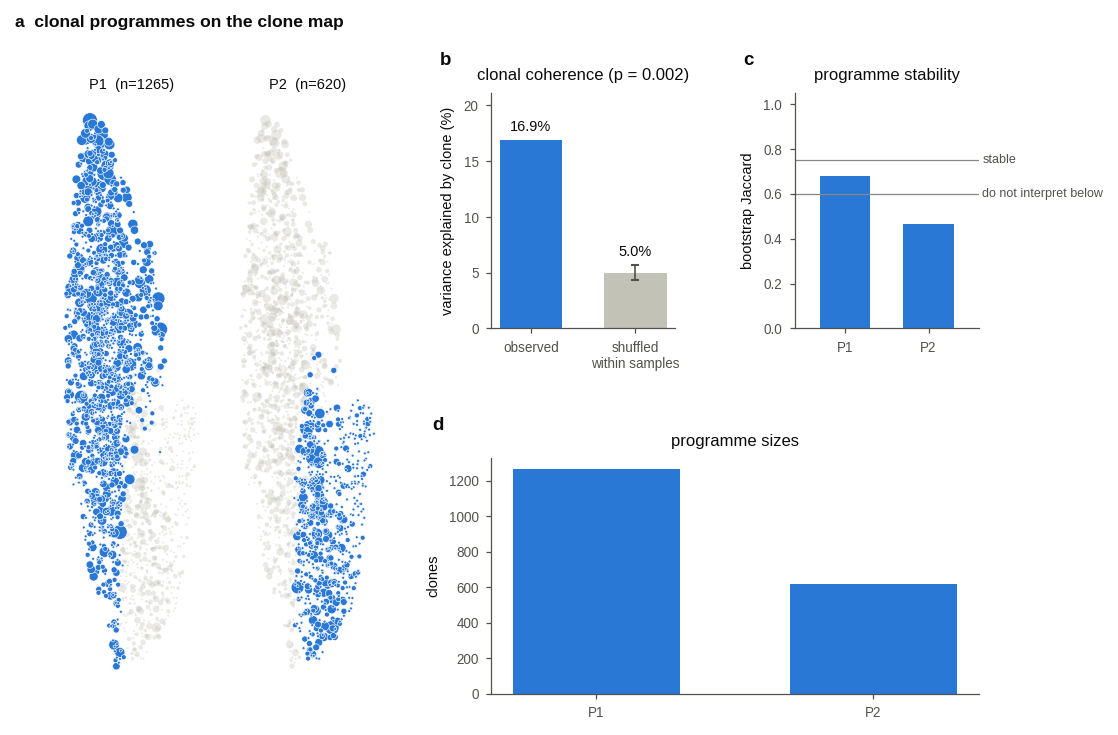

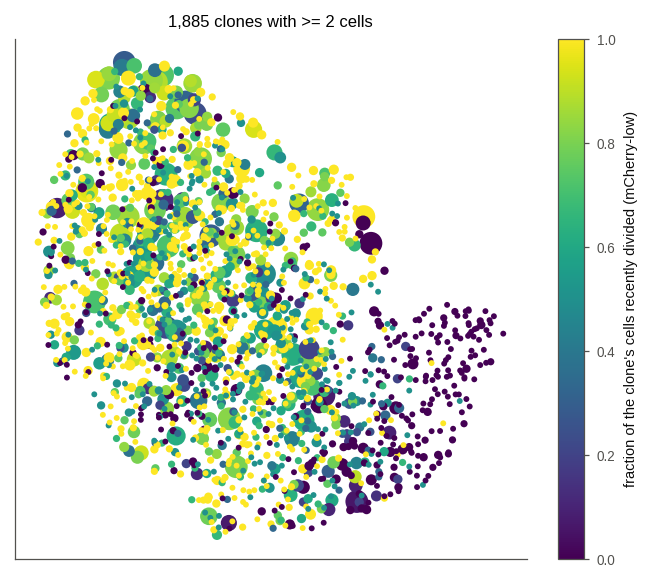

In [13]:
import matplotlib.pyplot as plt

result.plot("threadfin_tutorial_overview.png")
plt.show()

clones = result.clones.copy()
xy = clones[["x", "y"]]                                           # clone-map coordinates
division = tf.tl.clone_labels(adata, "division_gate", how="fraction:mCherry-low").reindex(clones.index)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
order = np.argsort(clones["n_cells"].to_numpy())[::-1]           # large clones underneath
points = ax.scatter(xy.iloc[order, 0], xy.iloc[order, 1], c=division.iloc[order], cmap="viridis",
                    s=np.clip(clones["n_cells"].iloc[order] * 4, 4, 120), linewidths=0)
fig.colorbar(points, label="fraction of the clone's cells recently divided (mCherry-low)")
ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"{len(clones):,} clones with >= 2 cells")
plt.show()

## Step 13 — Which measured annotations explain differences between clones?

**What.** `tf.tl.profile_association` asks how much of the variation between clone profiles is explained by
a clone-level annotation (here: the fraction of a clone's cells in a gate), and compares it with 2,000
random re-assignments of the annotation among clones **of the same mouse**. We test recent division in all
mice and in each cohort separately, RBD-bait binding in the protein cohort, and the dark-zone gate in the mRNA
cohort.

**How to read it.** `r2` is the share of profile variation explained; `null_mean` is what random
re-assignment gives; `excess_r2 = r2 − null_mean`; `p_value` is the permutation P value (smallest possible
1/2,001 ≈ 0.0005). Small R² values are expected: a sorting gate is one coarse measurement, and the profile
describes the whole transcriptome.

**The library caveat — read this before interpreting.** Each gate was sorted into its own sequencing tube,
so a gate effect could also be a tube effect. For **division**, the design crosses tubes between cohorts
(Step 4): a tube effect would push the profiles in *opposite* directions in the two cohorts, a division
effect in the *same* direction. We check that with the cosine similarity of the two cohorts' division
directions (manuscript: 0.89; a pure tube effect would give −1). **RBD-bait** and **dark-zone** gates were
both sorted into tubes C and D, so for them a biological effect cannot be separated from a tube effect, and
binding a bait is a sorting gate, not an affinity measurement.

In [14]:
def report(label, res):
    print(f"{label:38s} R2 = {res['r2']:.3f}  null = {res['null_mean']:.3f}  "
          f"excess = {res['excess_r2']:.3f}  P = {res['p_value']:.4f}  clones = {res['n_clones']}")


report("recent division, all mice", tf.tl.profile_association(
    adata, "division_gate", how="fraction:mCherry-low", n_perm=2000, verbose=False))
report("RBD-bait binding (protein cohort)", tf.tl.profile_association(
    adata, "rbd_bait", how="fraction:RBD+", n_perm=2000, verbose=False))
report("dark-zone gate (mRNA cohort)", tf.tl.profile_association(
    adata, "zone_gate", how="fraction:DZ", n_perm=2000, verbose=False))

# the same division test inside each cohort, and the agreement of the two division directions
features = adata.uns["threadfin"]["profiles"]["features"]
donor_of_clone = result.clones["donor"].astype(str)
arm_of_donor = adata.obs.groupby("donor", observed=True)["arm"].first().astype(str)
direction = {}
for arm in ["RBD protein", "RBD mRNA"]:
    ids = donor_of_clone.index[donor_of_clone.map(arm_of_donor).eq(arm).to_numpy()]
    y = division.loc[ids].to_numpy(float)
    X = features.loc[ids].to_numpy(float)
    keep = np.isfinite(y)
    Xc = X[keep] - X[keep].mean(axis=0)
    yc = y[keep] - y[keep].mean()
    beta = Xc.T @ yc / (yc @ yc)               # profile direction associated with recent division
    direction[arm] = beta
    r2 = float(np.sum((np.outer(yc, beta)) ** 2) / np.sum(Xc ** 2))
    print(f"{'recent division, ' + arm:38s} R2 = {r2:.3f}  clones = {int(keep.sum())}")
a, b = direction["RBD protein"], direction["RBD mRNA"]
print(f"\ncosine similarity of the two cohorts' division directions: {a @ b / np.linalg.norm(a) / np.linalg.norm(b):.2f}"
      "  (tube effect alone: -1)")

recent division, all mice              R2 = 0.087  null = 0.001  excess = 0.086  P = 0.0005  clones = 1885
RBD-bait binding (protein cohort)      R2 = 0.023  null = 0.001  excess = 0.023  P = 0.0005  clones = 1537


dark-zone gate (mRNA cohort)           R2 = 0.040  null = 0.003  excess = 0.037  P = 0.0005  clones = 348
recent division, RBD protein           R2 = 0.090  clones = 1537
recent division, RBD mRNA              R2 = 0.072  clones = 348

cosine similarity of the two cohorts' division directions: 0.90  (tube effect alone: -1)


## Step 14 — The main axis of clone profiles follows division history

**What.** Take the first principal component (PC1) of the clone profiles, divide the clones into ten equal
groups (deciles) along it, and plot the mean fraction of recently divided cells per decile for each cohort —
the analysis behind Figure 4d of the manuscript. PC1 is oriented so that it increases with a dark-zone /
cycling gene score.

**Why.** Programme labels are unstable here (Step 10), so instead of groups we look at the dominant
continuous axis of variation between clones and ask what it tracks. The gene score only orients the axis;
the division gate was never used to compute it.

**What to look for.** In both cohorts the recently divided fraction rises steadily from the lowest to the
highest decile (manuscript: from about 0.1 to 0.7–0.9).

PC1 explains 42% of the variation between clone profiles


arm     RBD mRNA  RBD protein
decile                       
1           0.14         0.11
2           0.42         0.40
3           0.76         0.60
4           0.69         0.62
5           0.79         0.64
6           0.81         0.69
7           0.81         0.71
8           0.82         0.69
9           0.90         0.70
10          0.85         0.72


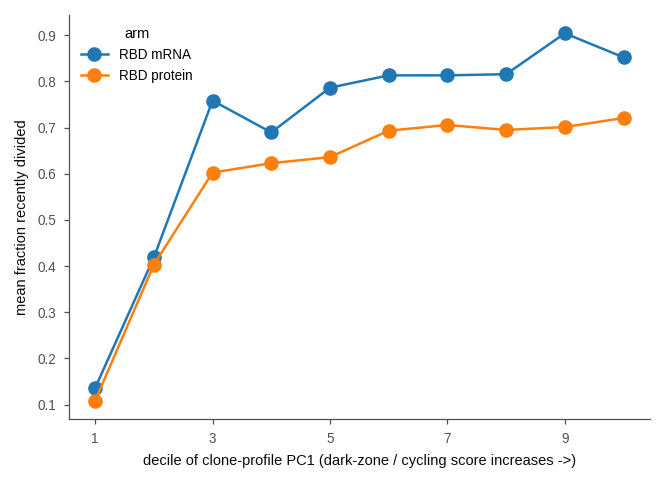

In [15]:
X = features.to_numpy(float)
X = X - X.mean(axis=0)
u, s, vt = np.linalg.svd(X, full_matrices=False)
pc1 = pd.Series(u[:, 0] * s[0], index=features.index)
print(f"PC1 explains {s[0] ** 2 / np.sum(s ** 2):.0%} of the variation between clone profiles")

dz_genes = ["Cxcr4", "Mki67", "Top2a", "Aurkb", "Ccnb1", "Hmgb2", "Stmn1", "Foxp1", "Aicda"]
log_norm = ad.AnnData(X=adata.layers["log_norm"], obs=adata.obs[[]], var=adata.var[[]])
sc.tl.score_genes(log_norm, [g for g in dz_genes if g in adata.var_names], score_name="dz_cycling", random_state=0)
adata.obs["dz_cycling"] = log_norm.obs["dz_cycling"].values
dz = adata.obs.dropna(subset=["clone_id"]).groupby("clone_id", observed=True)["dz_cycling"].mean()
if np.corrcoef(pc1, dz.reindex(pc1.index))[0, 1] < 0:
    pc1 = -pc1                                    # orient PC1 to increase with the dark-zone/cycling score

table = pd.DataFrame({"pc1": pc1, "divided": division.reindex(pc1.index),
                      "arm": donor_of_clone.reindex(pc1.index).map(arm_of_donor)})
table["decile"] = pd.qcut(table["pc1"].rank(method="first"), 10, labels=range(1, 11))
curve = table.groupby(["arm", "decile"], observed=True)["divided"].mean().unstack(0)
print(curve.round(2).to_string())
ax = curve.plot(marker="o", figsize=(5, 3.5))
ax.set_xlabel("decile of clone-profile PC1 (dark-zone / cycling score increases ->)")
ax.set_ylabel("mean fraction recently divided")
plt.show()

## Step 15 — Save the results

**What.** Write the annotated AnnData (with clone ids, profiles, programmes and tests in `adata.uns`) and
the clone table as files you can open in Python, R or a spreadsheet.

**Why.** `adata.uns["threadfin"]` keeps every result together with the settings that produced it, so the
analysis can be re-plotted or extended without re-running it.

In [16]:
out = Path("threadfin_tutorial_output")
out.mkdir(exist_ok=True)
result.clones.to_csv(out / "clones.csv")
result.programmes.to_csv(out / "programmes.csv")
adata.obs.to_csv(out / "cells.csv.gz")
adata.write_h5ad(out / "GSE287123_rbd_threadfin.h5ad", compression="gzip")
print(sorted(p.name for p in out.iterdir()))

['GSE287123_rbd_threadfin.h5ad', 'cells.csv.gz', 'clones.csv', 'programmes.csv']


## Step 16 — Where to go next

* [Tutorial 1](01_getting_started.md) runs the same analysis on simulated data in a minute and explains the
  overview figure; [Tutorial 2](02_your_data.md) starts from Cell Ranger output of your own experiment;
  [Tutorial 3](03_clone_map.md) explains the clone map and how to check it; [Tutorial 4](04_step_by_step.md)
  calls each function separately.
* [Methods](../METHODS.md) gives the statistical model of every step.
* [`manuscript/`](../../manuscript/README.md) holds every analysis of the manuscript, including this dataset
  (`manuscript/case_studies/results/mouse_rbd/`), and the benchmark against Clonotrace, clone2vec, Benisse
  and other tools.

**Common questions**

* *My clone ids do not match my cells.* Barcodes from different libraries must be made unique the same way
  in the expression and BCR tables (here: the `tube|` prefix).
* *Threadfin says too few clones have ≥ 2 cells.* Check that clones were called within donors and that the
  BCR barcodes matched; if your experiment truly sampled few cells per clone, coherence can still be tested
  but programmes may not be defined.
* *Which column should be the context (`sample_key`)?* A nuisance variable: the donor, or a technical batch.
  Never a tissue, time point, sort gate or treatment that you want to compare between clones.
* *Are programmes cell types?* No. A programme is a group of clones with similar distributions of states; use
  stability to decide whether it is a group at all.

In [17]:
print("threadfin", version("threadfin"), "| sc-dandelion", version("sc-dandelion"), "| scanpy", version("scanpy"),
      "| anndata", version("anndata"), "| python", sys.version.split()[0],
      "| PYTHONHASHSEED", os.environ.get("PYTHONHASHSEED"))

threadfin 4.3.1 | sc-dandelion 0.5.7 | scanpy 1.11.5 | anndata 0.12.19 | python 3.11.17 | PYTHONHASHSEED 0
